# ML Assignment 2 — Online Shoppers Purchasing Intention
**M.Tech (AIML) · Machine Learning · BITS Pilani WILP**

| | |
|---|---|
| **Student Name** | _<your name>_ |
| **BITS ID** | _<your id>_ |
| **Dataset** | [UCI #468 — Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) |

### Problem statement
An e-commerce site records each browsing **session** (pages visited, time spent, bounce/exit rates, page value, month, visitor type, …).
The goal is to predict whether a session will end in a **purchase** (`Revenue = True`) — a **binary classification** problem.

This notebook:
1. Explores and preprocesses the dataset
2. Trains 5 classifiers — Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM
3. Evaluates each on a held-out test set with **Accuracy, AUC, Precision, Recall, F1, MCC**
4. Saves the trained pipelines to `model/` and the test split to `test_data.csv` for the Streamlit app

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

SEED = 2026
DATA_PATH = Path("data/online_shoppers_intention.csv")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 2. Load and inspect the data

In [2]:
raw_df = pd.read_csv(DATA_PATH)
print("Shape:", raw_df.shape)
raw_df.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [4]:
raw_df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


In [5]:
print("Missing values per column:", int(raw_df.isna().sum().sum()))
print("Duplicate rows:", raw_df.duplicated().sum())
print("\nTarget distribution:")
print(raw_df["Revenue"].value_counts().rename({False: "No purchase", True: "Purchase"}))
print(raw_df["Revenue"].value_counts(normalize=True).round(3))

Missing values per column: 0


Duplicate rows: 125

Target distribution:


Revenue
No purchase    10422
Purchase        1908
Name: count, dtype: int64
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


### Dataset description
| Feature | Type | Meaning |
|---|---|---|
| Administrative, Informational, ProductRelated | int | Number of pages of each type visited in the session |
| *_Duration (3 cols) | float | Seconds spent on each page type |
| BounceRates | float | % of visitors who entered on a page and left without another request |
| ExitRates | float | % of pageviews where the page was the last in the session |
| PageValues | float | Average value of pages visited before a transaction (Google Analytics) |
| SpecialDay | float | Closeness of the visit to a special day (e.g. Mother's Day) — 0 to 1 |
| Month | categorical | Month of the visit |
| OperatingSystems, Browser, Region, TrafficType | categorical (coded ints) | Technical / traffic-source info |
| VisitorType | categorical | Returning / New / Other |
| Weekend | bool | Visit on a weekend |
| **Revenue** | **bool (target)** | **Whether the session ended in a purchase** |

**17 input features, 12,330 instances, no missing values.** The classes are imbalanced (~15.5 % purchases), so
F1, AUC and MCC are more informative than accuracy alone.

## 3. Exploratory data analysis

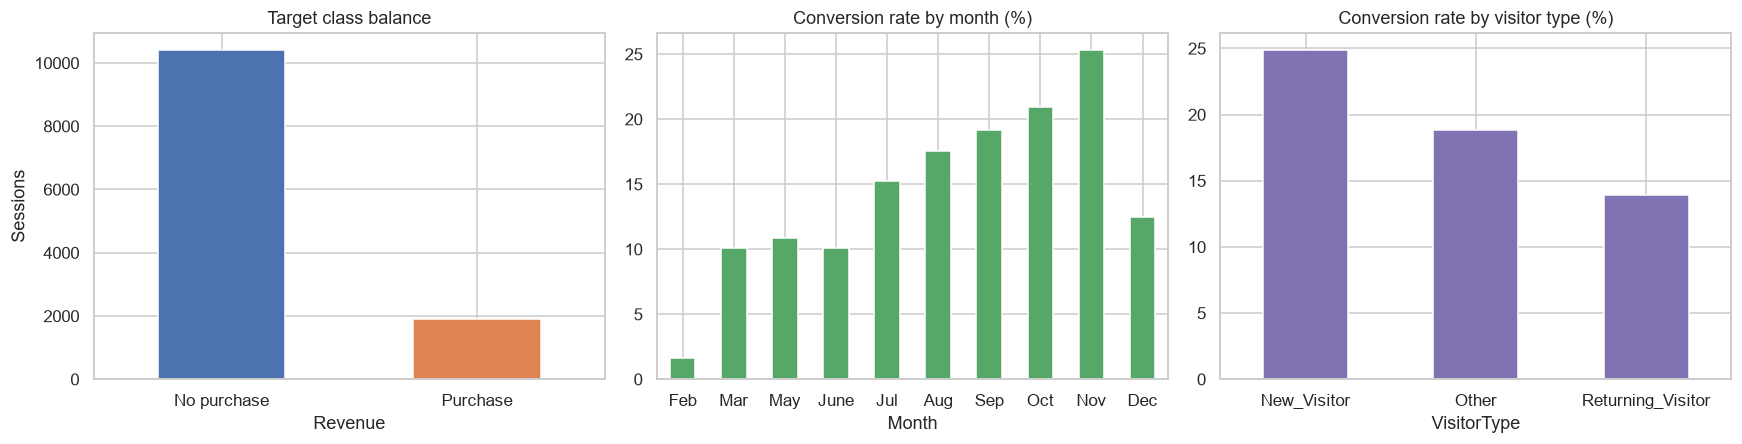

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

raw_df["Revenue"].map({False: "No purchase", True: "Purchase"}).value_counts().plot.bar(
    ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0)
axes[0].set_title("Target class balance")
axes[0].set_ylabel("Sessions")

month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
conv = raw_df.groupby("Month")["Revenue"].mean().reindex(month_order) * 100
conv.plot.bar(ax=axes[1], color="#55A868", rot=0)
axes[1].set_title("Conversion rate by month (%)")

conv_vt = raw_df.groupby("VisitorType")["Revenue"].mean() * 100
conv_vt.plot.bar(ax=axes[2], color="#8172B3", rot=0)
axes[2].set_title("Conversion rate by visitor type (%)")
plt.tight_layout()
plt.show()

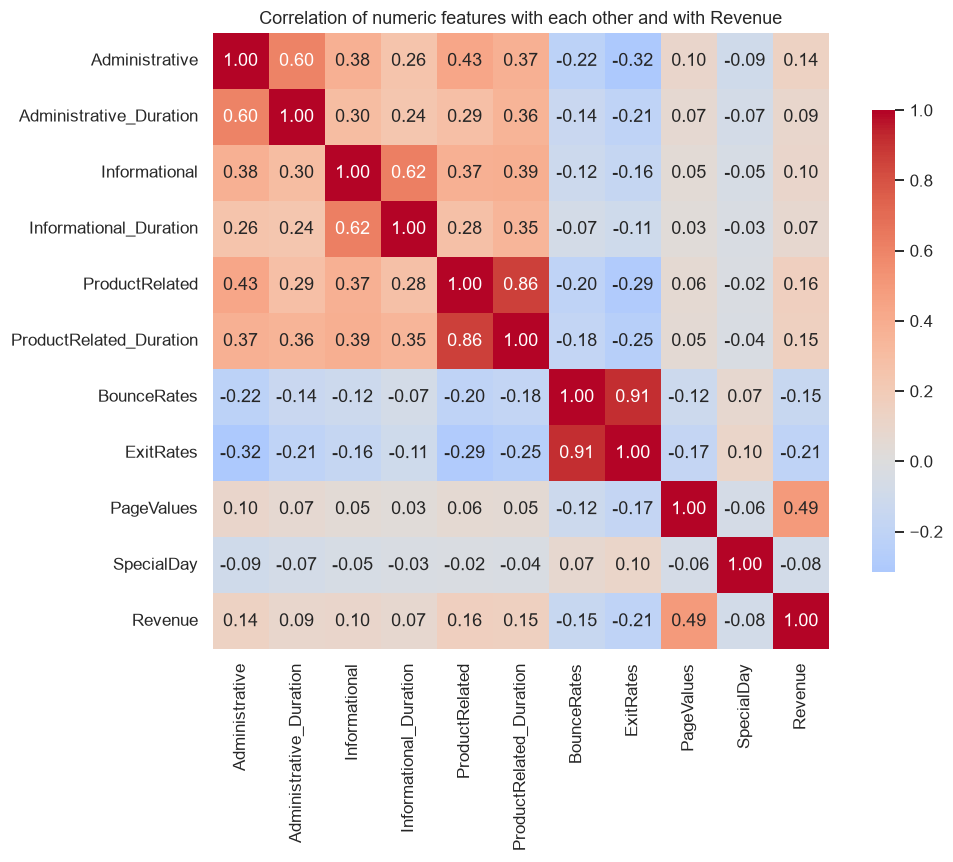

In [7]:
num_cols_eda = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
                "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
                "PageValues", "SpecialDay"]
plt.figure(figsize=(10, 8))
corr = raw_df[num_cols_eda + ["Revenue"]].astype(float).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .75})
plt.title("Correlation of numeric features with each other and with Revenue")
plt.tight_layout()
plt.show()

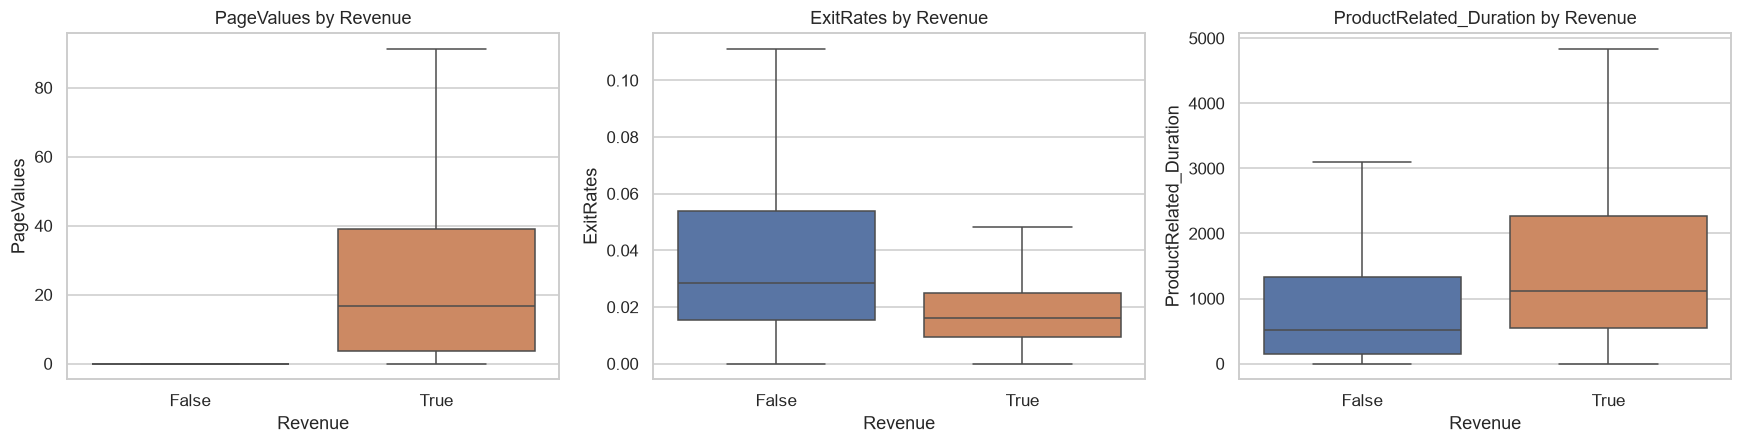

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, ["PageValues", "ExitRates", "ProductRelated_Duration"]):
    sns.boxplot(data=raw_df, x="Revenue", y=col, ax=ax, showfliers=False,
                hue="Revenue", palette=["#4C72B0", "#DD8452"], legend=False)
    ax.set_title(f"{col} by Revenue")
plt.tight_layout()
plt.show()

**EDA takeaways**
- `PageValues` is by far the strongest signal (corr ≈ 0.49 with Revenue); purchasing sessions have much higher page values.
- `BounceRates` and `ExitRates` are highly correlated with each other (≈ 0.91) and negatively related to purchase.
- November has the highest conversion rate; new visitors convert more often than returning ones.
- Duration features are heavily right-skewed → scaling is needed for distance/margin-based models (KNN, SVM, LR).

## 4. Preprocessing

In [9]:
TARGET = "Revenue"
NUMERIC_FEATURES = num_cols_eda + ["Weekend"]
CATEGORICAL_FEATURES = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

def to_binary(series):
    """Turn True/False, 'TRUE'/'FALSE' or 1/0 into 0/1 integers."""
    return series.astype(str).str.strip().str.lower().map({"true": 1, "1": 1, "false": 0, "0": 0}).astype(int)

df = raw_df.drop_duplicates().reset_index(drop=True).copy()
df["Weekend"] = to_binary(df["Weekend"])
df[TARGET] = to_binary(df[TARGET])
for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype(str)

print("Rows after dropping duplicates:", len(df))
print("Numeric features   :", len(NUMERIC_FEATURES))
print("Categorical features:", len(CATEGORICAL_FEATURES))

Rows after dropping duplicates: 12205
Numeric features   : 11
Categorical features: 6


In [10]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Purchase rate  train = %.3f  test = %.3f" % (y_train.mean(), y_test.mean()))

# Save the raw (un-scaled) test split, with target, for the Streamlit app
test_export = X_test.copy()
test_export[TARGET] = y_test
test_export.to_csv("test_data.csv", index=False)
print("Saved test_data.csv with", len(test_export), "rows")

Train: (9764, 17)  Test: (2441, 17)
Purchase rate  train = 0.156  test = 0.156


Saved test_data.csv with 2441 rows


In [11]:
def make_preprocessor():
    """Scale numeric columns, one-hot encode categorical columns."""
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ])

## 5. Model training
Each model is a `Pipeline(preprocessor → classifier)`, so the saved file takes **raw** CSV columns as input.
Hyper-parameters are tuned with 5-fold stratified `GridSearchCV`, optimising **F1** (because of class imbalance).

In [12]:
model_specs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=SEED),
        {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": [1, 5, 20],
         "clf__class_weight": [None, "balanced"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 31], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]}),
    "Support Vector Machine": (
        SVC(kernel="rbf", random_state=SEED),
        {"clf__C": [0.5, 1, 3], "clf__class_weight": [None, "balanced"]}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted_models = {}
for name, (estimator, grid) in model_specs.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", estimator)])
    search = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    fitted_models[name] = search.best_estimator_
    best = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:<24} CV-F1 = {search.best_score_:.4f}   best params: {best}")

Logistic Regression      CV-F1 = 0.6139   best params: {'C': 0.01, 'class_weight': 'balanced'}


Decision Tree            CV-F1 = 0.6303   best params: {'class_weight': 'balanced', 'max_depth': 4, 'min_samples_leaf': 20}


KNN                      CV-F1 = 0.4774   best params: {'n_neighbors': 5, 'weights': 'uniform'}


Naive Bayes              CV-F1 = 0.5089   best params: {'var_smoothing': 0.1}


Support Vector Machine   CV-F1 = 0.6381   best params: {'C': 1, 'class_weight': 'balanced'}


## 6. Evaluation on the test set

In [13]:
def positive_scores(model, X):
    """Score for the positive class, used for AUC / ROC (SVC has no predict_proba)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def evaluate(model, X, y):
    y_pred = model.predict(X)
    return {
        "Accuracy": accuracy_score(y, y_pred),
        "AUC": roc_auc_score(y, positive_scores(model, X)),
        "Precision": precision_score(y, y_pred, zero_division=0),
        "Recall": recall_score(y, y_pred),
        "F1": f1_score(y, y_pred),
        "MCC": matthews_corrcoef(y, y_pred),
    }

results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in fitted_models.items()}).T
results.index.name = "ML Model Name"
results.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8669,0.9084,0.5556,0.7461,0.6369,0.5666
Decision Tree,0.8689,0.9310,0.5522,0.8586,0.6721,0.6176
KNN,0.8763,0.7843,0.6923,0.3770,0.4881,0.4501
Naive Bayes,0.8177,0.8241,0.4418,0.6257,0.5179,0.4190
Support Vector Machine,0.8816,0.9188,0.5955,0.7592,0.6674,0.6032


In [14]:
results.style.format("{:.4f}").background_gradient(cmap="Greens", axis=0)

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8669,0.9084,0.5556,0.7461,0.6369,0.5666
Decision Tree,0.8689,0.9310,0.5522,0.8586,0.6721,0.6176
KNN,0.8763,0.7843,0.6923,0.3770,0.4881,0.4501
Naive Bayes,0.8177,0.8241,0.4418,0.6257,0.5179,0.4190
Support Vector Machine,0.8816,0.9188,0.5955,0.7592,0.6674,0.6032


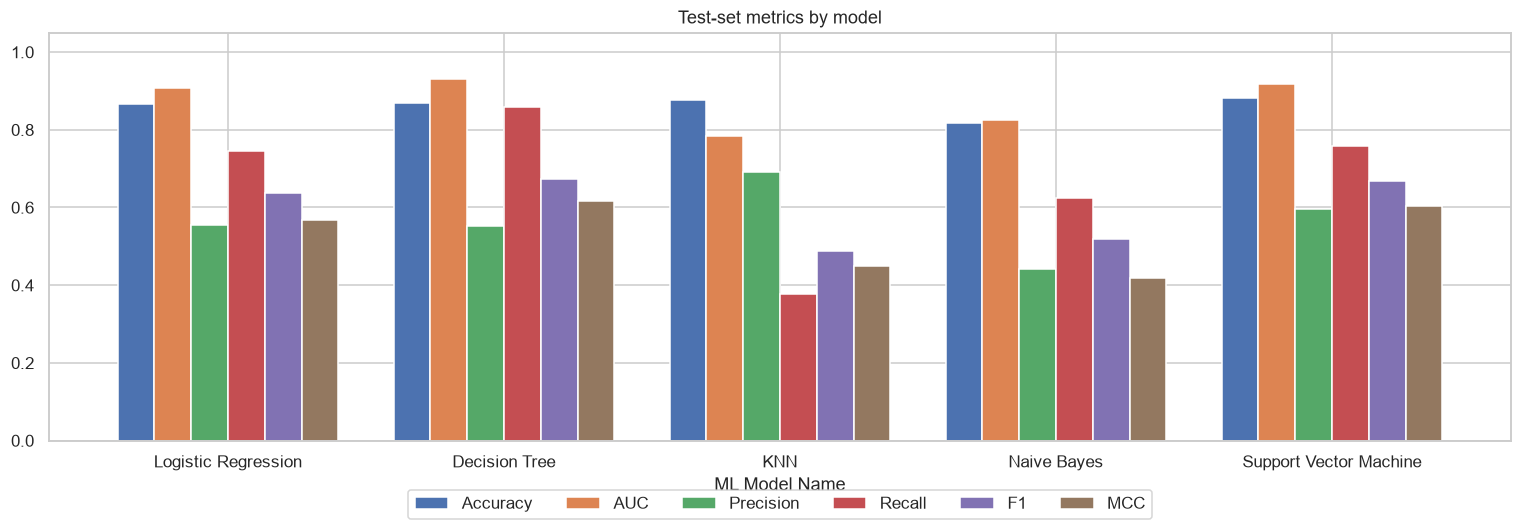

In [15]:
ax = results.plot.bar(figsize=(14, 5), rot=0, width=0.8)
ax.set_ylim(0, 1.05)
ax.set_title("Test-set metrics by model")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

### Confusion matrices

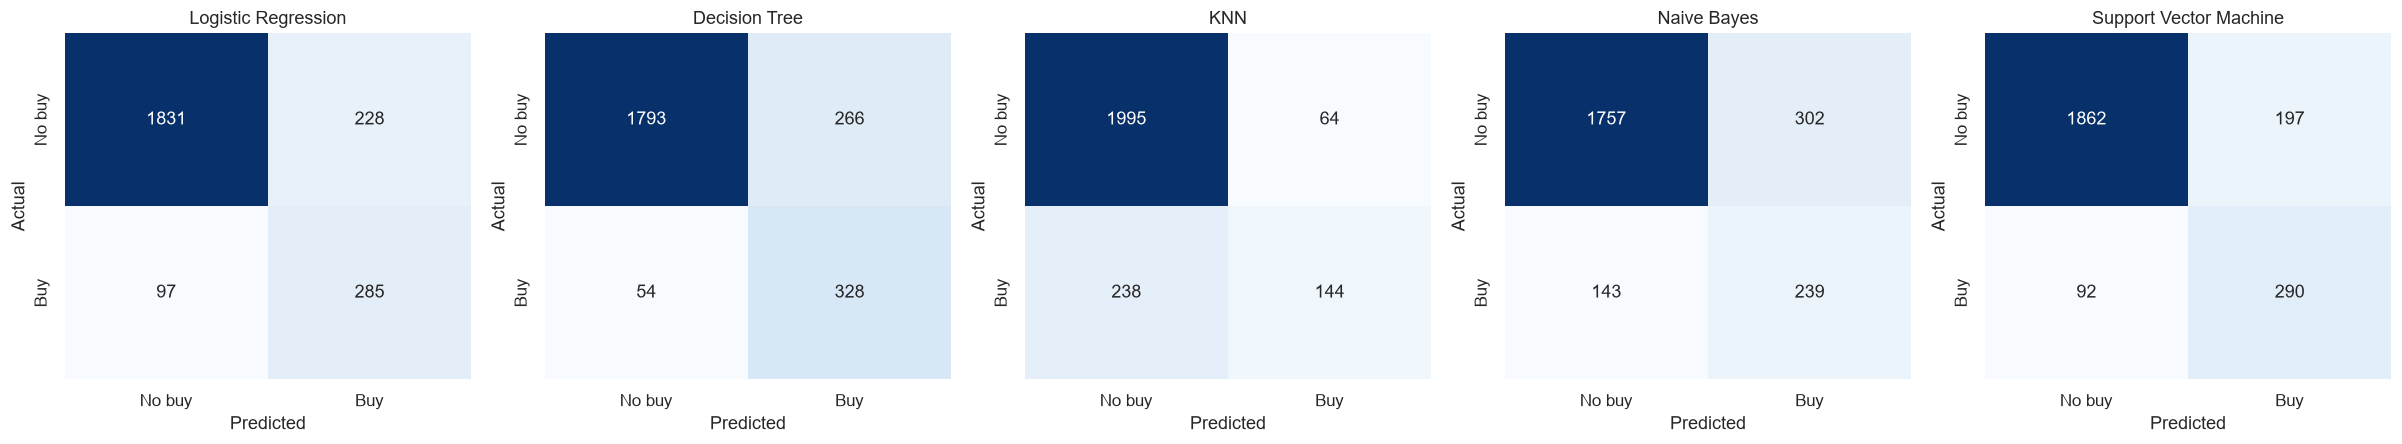

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, (name, model) in zip(axes, fitted_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No buy", "Buy"], yticklabels=["No buy", "Buy"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### ROC curves

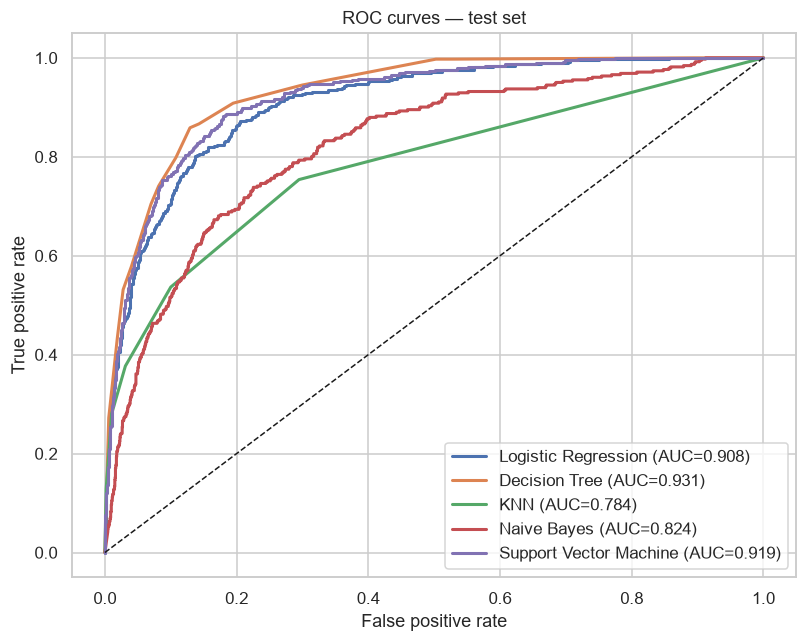

In [17]:
plt.figure(figsize=(7.5, 6))
for name, model in fitted_models.items():
    fpr, tpr, _ = roc_curve(y_test, positive_scores(model, X_test))
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC={results.loc[name, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves — test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Classification reports

In [18]:
for name, model in fitted_models.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, model.predict(X_test), target_names=["No purchase", "Purchase"], digits=4))

Logistic Regression
              precision    recall  f1-score   support

 No purchase     0.9497    0.8893    0.9185      2059
    Purchase     0.5556    0.7461    0.6369       382

    accuracy                         0.8669      2441
   macro avg     0.7526    0.8177    0.7777      2441
weighted avg     0.8880    0.8669    0.8744      2441

Decision Tree
              precision    recall  f1-score   support

 No purchase     0.9708    0.8708    0.9181      2059
    Purchase     0.5522    0.8586    0.6721       382

    accuracy                         0.8689      2441
   macro avg     0.7615    0.8647    0.7951      2441
weighted avg     0.9053    0.8689    0.8796      2441

KNN


              precision    recall  f1-score   support

 No purchase     0.8934    0.9689    0.9296      2059
    Purchase     0.6923    0.3770    0.4881       382

    accuracy                         0.8763      2441
   macro avg     0.7929    0.6729    0.7089      2441
weighted avg     0.8619    0.8763    0.8605      2441

Naive Bayes
              precision    recall  f1-score   support

 No purchase     0.9247    0.8533    0.8876      2059
    Purchase     0.4418    0.6257    0.5179       382

    accuracy                         0.8177      2441
   macro avg     0.6833    0.7395    0.7027      2441
weighted avg     0.8492    0.8177    0.8297      2441

Support Vector Machine


              precision    recall  f1-score   support

 No purchase     0.9529    0.9043    0.9280      2059
    Purchase     0.5955    0.7592    0.6674       382

    accuracy                         0.8816      2441
   macro avg     0.7742    0.8317    0.7977      2441
weighted avg     0.8970    0.8816    0.8872      2441



## 7. Save models and artifacts

In [19]:
file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib",
}
for name, model in fitted_models.items():
    joblib.dump(model, MODEL_DIR / file_names[name])

results.round(4).to_csv(MODEL_DIR / "test_metrics.csv")
with open(MODEL_DIR / "model_info.json", "w") as f:
    json.dump({"target": TARGET, "numeric_features": NUMERIC_FEATURES,
               "categorical_features": CATEGORICAL_FEATURES, "models": file_names,
               "sklearn_version": sklearn.__version__}, f, indent=2)

for p in sorted(MODEL_DIR.iterdir()):
    print(f"{p.name:<28} {p.stat().st_size/1024:8.1f} KB")

decision_tree.joblib              8.1 KB
knn.joblib                     5726.3 KB
logistic_regression.joblib        5.8 KB
model_info.json                   0.7 KB
naive_bayes.joblib                7.4 KB
svm.joblib                     2565.8 KB
test_metrics.csv                  0.3 KB


In [20]:
# Sanity check: reload one model from disk and confirm identical predictions
reloaded = joblib.load(MODEL_DIR / "svm.joblib")
assert (reloaded.predict(X_test) == fitted_models["Support Vector Machine"].predict(X_test)).all()
print("Reloaded model predictions match ✔")

Reloaded model predictions match ✔


## 8. Observations

| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Solid linear baseline (AUC 0.908, F1 0.637). Tuning chose strong regularisation (C = 0.01) with balanced class weights, which lifted purchase recall to 0.75 at the cost of precision (0.56). Its linear boundary cannot capture the threshold-like effect of `PageValues`, so it trails the tree and SVM. |
| **Decision Tree** | Best overall: highest AUC (0.931), F1 (0.672), MCC (0.618) and recall (0.859). A shallow tree (depth 4, min 20 samples per leaf) is enough because `PageValues > 0` is an almost rule-like split for purchases; the depth limit keeps it from overfitting. Precision (0.55) is moderate because balanced weights make it flag more sessions as buyers. |
| **KNN** | Highest precision (0.69) and good accuracy (0.876) but the weakest recall (0.38), F1 (0.488) and AUC (0.784). With 63 one-hot columns, distances are dominated by sparse categorical dimensions, and majority voting favours the 84 % "no purchase" class — so it misses most buyers. |
| **Naive Bayes** | Lowest accuracy (0.818) and MCC (0.419). The Gaussian independence assumption is violated (BounceRates and ExitRates are ~0.91 correlated; durations are highly skewed, not normal) and one-hot features are not Gaussian. A large `var_smoothing` (0.1) was needed to make it stable. Fast and simple, but the least reliable here. |
| **Support Vector Machine** | Close second: best accuracy (0.882), AUC 0.919, F1 0.667, MCC 0.603. The RBF kernel with balanced class weights captures the non-linear interactions better than Logistic Regression, with a better precision/recall balance (0.60 / 0.76) than the tree. Slowest model to train and the largest saved file. |
| **Overall winner** | **Decision Tree** — best F1, AUC, MCC and recall, while also being small, fast and easy to explain. Accuracy alone is misleading on this imbalanced data (predicting "no purchase" always would score 84 %), so F1 and MCC were used to pick the winner. SVM is a strong alternative when precision matters more. |
